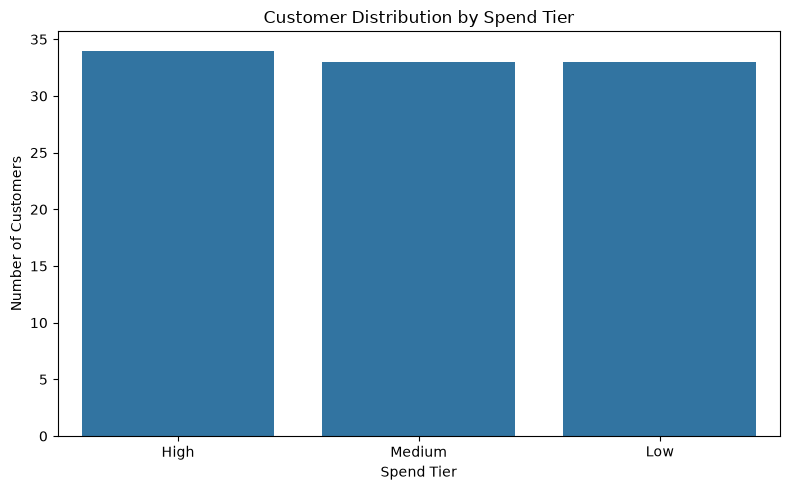

In [9]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Load query from queries/clv_analysis.sql and execute
base_dir = Path.cwd()
db_path = base_dir / "data" / "store.db"

# Jupyter may run from the project root or from the notebooks folder
if not db_path.exists():
    db_path = (base_dir.parent / "data" / "store.db").resolve()

conn = sqlite3.connect(str(db_path))
query_path = base_dir / "queries" / "clv_analysis.sql"
if not query_path.exists():
    query_path = (base_dir.parent / "queries" / "clv_analysis.sql").resolve()

with open(query_path, "r", encoding="utf-8") as f:
    query = f.read()
df = pd.read_sql_query(query, conn)
conn.close()

plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='value_tier', order=['High', 'Medium', 'Low'])
plt.xlabel('Spend Tier')
plt.ylabel('Number of Customers')
plt.title('Customer Distribution by Spend Tier')
plt.tight_layout()
project_root = base_dir if (base_dir / "data").exists() else base_dir.parent
fig_path = project_root / "notebooks" / "clv_distribution.png"
fig_path.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(fig_path)
plt.show()